In [4]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Go from notebooks/ to the project root
PROJECT_ROOT = Path.cwd().parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "loan_default_dataset.csv"
)

print("CSV path:", DATA_PATH)
print("File exists:", DATA_PATH.exists())

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

CSV path: e:\BW\ML projects\loan_default_prediction\data\raw\loan_default_dataset.csv
File exists: True
Dataset loaded successfully!
Shape: (10, 15)


,,CUSTOMER_ID,AGE,GENDER,INCOME,EMPLOYMENT_YEARS,CITY,LOAN_AMOUNT,LOAN_TERM,INTEREST_RATE,LOAN_TYPE,CREDIT_SCORE,PREVIOUS_DEFAULTS,NUMBER_OF_LOANS,DEFAULT_STATUS
0,1,1001,25,Male,45000,2,Pune,250000,36,11.5,Personal,680,0,2,1
1,2,1002,34,Female,72000,8,Mumbai,450000,60,8.5,Home,780,0,3,0
2,3,1003,29,Male,52000,4,Delhi,300000,48,10.2,Auto,710,1,2,0
3,4,1004,42,Female,95000,15,Bangalore,700000,60,7.8,Home,820,0,4,0
4,5,1005,31,Male,38000,3,Hyderabad,200000,36,13.5,Personal,610,2,3,1


In [5]:
print("Number of columns:", len(df.columns))

for i, col in enumerate(df.columns, start=1):
    print(i, repr(col))

Number of columns: 15
1 '   '
2 'CUSTOMER_ID'
3 'AGE'
4 'GENDER'
5 'INCOME'
6 'EMPLOYMENT_YEARS'
7 'CITY'
8 'LOAN_AMOUNT'
9 'LOAN_TERM'
10 'INTEREST_RATE'
11 'LOAN_TYPE'
12 'CREDIT_SCORE'
13 'PREVIOUS_DEFAULTS'
14 'NUMBER_OF_LOANS'
15 'DEFAULT_STATUS'


In [6]:
print(df.iloc[:, 0].head(10).tolist())

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]


In [8]:
# Remove whitespace from column names
df.columns = df.columns.str.strip()

# Remove columns with empty names
df = df.loc[:, df.columns != ""]

print("Updated shape:", df.shape)
print(df.columns.tolist())

Updated shape: (10, 14)
['CUSTOMER_ID', 'AGE', 'GENDER', 'INCOME', 'EMPLOYMENT_YEARS', 'CITY', 'LOAN_AMOUNT', 'LOAN_TERM', 'INTEREST_RATE', 'LOAN_TYPE', 'CREDIT_SCORE', 'PREVIOUS_DEFAULTS', 'NUMBER_OF_LOANS', 'DEFAULT_STATUS']


In [ ]:
print("Shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nStatistical summary:")
display(df.describe(include="all").T)

In [10]:
# Check target values and their counts
print(df["DEFAULT_STATUS"].value_counts(dropna=False))

# Check target proportions
print("\nTarget proportions:")
print(df["DEFAULT_STATUS"].value_counts(normalize=True, dropna=False) * 100)

DEFAULT_STATUS
0    6
1    4
Name: count, dtype: int64

Target proportions:
DEFAULT_STATUS
0    60.0
1    40.0
Name: proportion, dtype: float64


In [11]:
# Select numerical columns
numeric_cols = df.select_dtypes(include="number").columns.tolist()

print("Numerical columns:")
print(numeric_cols)

# Summary statistics
df[numeric_cols].describe().T

Numerical columns:
['CUSTOMER_ID', 'AGE', 'INCOME', 'EMPLOYMENT_YEARS', 'LOAN_AMOUNT', 'LOAN_TERM', 'INTEREST_RATE', 'CREDIT_SCORE', 'PREVIOUS_DEFAULTS', 'NUMBER_OF_LOANS', 'DEFAULT_STATUS']


,count,mean,std,min,25%,50%,75%,max
CUSTOMER_ID,10.0,1005.50,3.027650,1001.0,1003.250,1005.50,1007.750,1010.0
AGE,10.0,34.50,9.264628,23.0,27.500,32.50,41.000,51.0
INCOME,10.0,65600.00,28519.778712,30000.0,45750.000,60000.00,84000.000,120000.0
EMPLOYMENT_YEARS,10.0,8.90,8.171087,1.0,2.250,6.00,14.000,25.0
LOAN_AMOUNT,10.0,380500.00,175664.610994,180000.0,256250.000,325000.00,487500.000,700000.0
LOAN_TERM,10.0,49.20,10.507140,36.0,39.000,48.00,60.000,60.0
INTEREST_RATE,10.0,10.29,2.407604,7.5,8.275,9.85,11.875,14.2
CREDIT_SCORE,10.0,721.00,86.980202,590.0,657.500,725.00,795.000,830.0
PREVIOUS_DEFAULTS,10.0,0.60,0.843274,0.0,0.000,0.00,1.000,2.0
NUMBER_OF_LOANS,10.0,3.00,1.054093,2.0,2.000,3.00,3.750,5.0


In [12]:
df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
CUSTOMER_ID,10.0,1005.50,3.027650,1001.0,1003.250,1005.50,1007.750,1010.0
AGE,10.0,34.50,9.264628,23.0,27.500,32.50,41.000,51.0
INCOME,10.0,65600.00,28519.778712,30000.0,45750.000,60000.00,84000.000,120000.0
EMPLOYMENT_YEARS,10.0,8.90,8.171087,1.0,2.250,6.00,14.000,25.0
LOAN_AMOUNT,10.0,380500.00,175664.610994,180000.0,256250.000,325000.00,487500.000,700000.0
LOAN_TERM,10.0,49.20,10.507140,36.0,39.000,48.00,60.000,60.0
INTEREST_RATE,10.0,10.29,2.407604,7.5,8.275,9.85,11.875,14.2
CREDIT_SCORE,10.0,721.00,86.980202,590.0,657.500,725.00,795.000,830.0
PREVIOUS_DEFAULTS,10.0,0.60,0.843274,0.0,0.000,0.00,1.000,2.0
NUMBER_OF_LOANS,10.0,3.00,1.054093,2.0,2.000,3.00,3.750,5.0


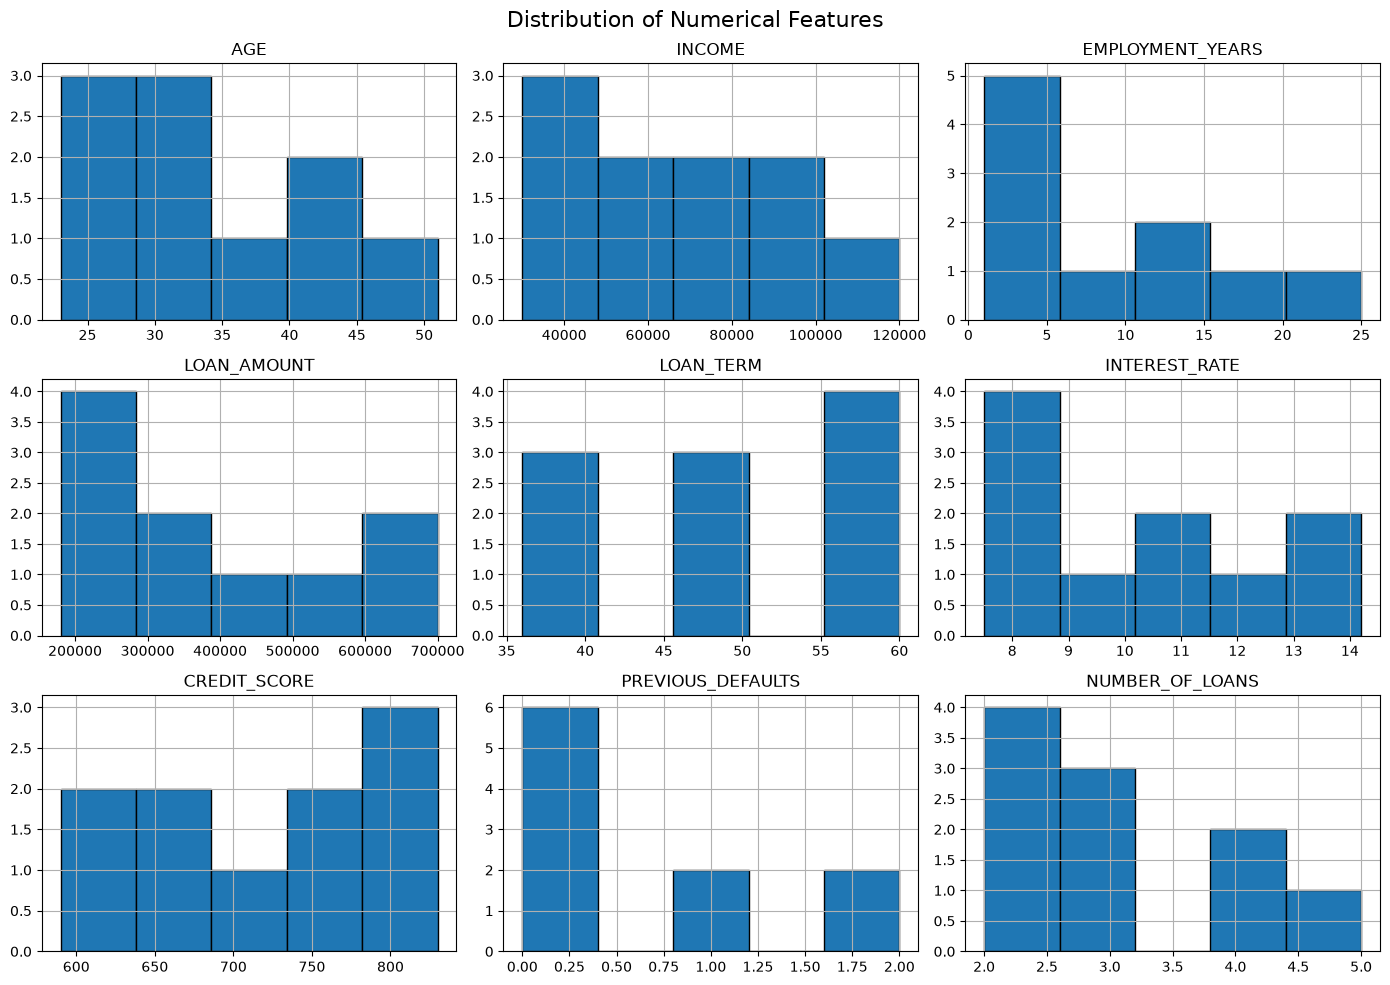

In [13]:
# Select numerical input features
numeric_features = df.select_dtypes(include="number").columns.tolist()

numeric_features = [
    col for col in numeric_features
    if col not in ["CUSTOMER_ID", "DEFAULT_STATUS"]
]

# Plot histograms
df[numeric_features].hist(
    figsize=(14, 10),
    bins=5,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

In [14]:
# Compare numerical feature averages for each target class
default_comparison = df.groupby("DEFAULT_STATUS")[numeric_features].mean().T

default_comparison.columns = ["No Default (0)", "Default (1)"]

default_comparison["Difference"] = (
    default_comparison["Default (1)"]
    - default_comparison["No Default (0)"]
)

default_comparison

,No Default (0),Default (1),Difference
AGE,39.833333,26.50,-13.333333
INCOME,82500.000000,40250.00,-42250.000000
EMPLOYMENT_YEARS,13.500000,2.00,-11.500000
LOAN_AMOUNT,483333.333333,226250.00,-257083.333333
LOAN_TERM,56.000000,39.00,-17.000000
INTEREST_RATE,8.616667,12.80,4.183333
CREDIT_SCORE,780.000000,632.50,-147.500000
PREVIOUS_DEFAULTS,0.166667,1.25,1.083333
NUMBER_OF_LOANS,3.500000,2.25,-1.250000


In [15]:
display(default_comparison.round(2))

,No Default (0),Default (1),Difference
AGE,39.83,26.50,-13.33
INCOME,82500.00,40250.00,-42250.00
EMPLOYMENT_YEARS,13.50,2.00,-11.50
LOAN_AMOUNT,483333.33,226250.00,-257083.33
LOAN_TERM,56.00,39.00,-17.00
INTEREST_RATE,8.62,12.80,4.18
CREDIT_SCORE,780.00,632.50,-147.50
PREVIOUS_DEFAULTS,0.17,1.25,1.08
NUMBER_OF_LOANS,3.50,2.25,-1.25
